# Convolutional Neural Network 실습 (TensorFlow/Keras + MNIST)

이 노트북에서는 Convolution과 Pooling의 개념을 실습합니다.

## 주요 포인트
- Convolution: kernel size, padding, stride, dilation, filter 개수, bias
- Pooling: MaxPooling vs AveragePooling


In [1]:
%matplotlib inline
import os
import logging
import platform
import sys
import numpy as np
import matplotlib.pyplot as plt
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
from tensorflow.keras import layers, models
from pathlib import Path as _Path

tf.get_logger().setLevel("ERROR")
logging.getLogger("tensorflow").setLevel(logging.ERROR)

if platform.system() == "Windows":
    plt.rc("font", family="Malgun Gothic")
elif platform.system() == "Darwin":
    plt.rc("font", family="AppleGothic")
else:
    plt.rc("font", family="NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

tf.random.set_seed(42)
np.random.seed(42)

_root = next(
    p for p in [_Path.cwd().resolve(), *_Path.cwd().resolve().parents]
    if (p / ".cursor" / "runtime_device.py").exists()
)
if str(_root / ".cursor") not in sys.path:
    sys.path.insert(0, str(_root / ".cursor"))
import runtime_device
runtime_device.configure_tensorflow(tf)
print("TensorFlow 버전:", tf.__version__)


OS: Darwin
학습 장치: MPS (Apple GPU) [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
배치된 장치: /job:localhost/replica:0/task:0/device:GPU:0
TensorFlow 버전: 2.17.1


## [1] MNIST 데이터 로드 및 전처리

Train shape: (60000, 28, 28, 1)
Test shape: (10000, 28, 28, 1)


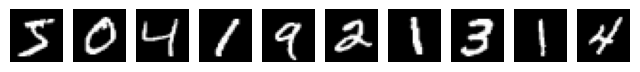

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

print('Train shape:', x_train.shape)
print('Test shape:', x_test.shape)

plt.figure(figsize=(8, 2))
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.axis('off')
plt.show()

## [2] Convolution 실습
### 2.1 Kernel size & Padding

In [3]:
sample = x_train[0:1]

conv_valid = layers.Conv2D(filters=1, kernel_size=(3,3), padding='valid', use_bias=False)
conv_same = layers.Conv2D(filters=1, kernel_size=(3,3), padding='same', use_bias=False)

out_valid = conv_valid(sample)
out_same = conv_same(sample)

print('입력:', sample.shape)
print('valid 출력:', out_valid.shape)
print('same 출력:', out_same.shape)

입력: (1, 28, 28, 1)
valid 출력: (1, 26, 26, 1)
same 출력: (1, 28, 28, 1)


### [생각해보기 - Padding]
1. valid padding과 same padding은 출력 크기가 어떻게 달라지나요?
2. 층을 깊게 쌓을 때 same padding을 자주 쓰는 이유는 무엇인가요?


**나의 답변:**

1. valid는 가장자리를 채우지 않아, 28x28에 3x3 커널이면 출력이 26x26으로 줄어든다.  
   반면 same은 0으로 가장자리를 채워 입력과 출력 크기를 맞춘다.  
   이번 실습에서도 valid는 (1, 26, 26, 1), same은 (1, 28, 28, 1)이었다.

2. padding이 없으면 층을 쌓을수록 특징 맵이 너무 빨리 작아진다.  
   그래서 same을 쓰면 공간 정보를 지키면서 Convolution을 반복할 수 있다.


### 2.2 Stride와 Dilation

In [4]:
conv_stride = layers.Conv2D(1, (3,3), strides=(2,2), padding='same', use_bias=False)
conv_dilated = layers.Conv2D(1, (3,3), dilation_rate=(2,2), padding='same', use_bias=False)

out_stride = conv_stride(sample)
out_dilated = conv_dilated(sample)

print('stride=2 출력:', out_stride.shape)
print('dilation=2 출력:', out_dilated.shape)

stride=2 출력: (1, 14, 14, 1)
dilation=2 출력: (1, 28, 28, 1)


### [생각해보기 - Stride와 Dilation]
1. Stride를 키우면 특징 맵과 수용 영역은 어떻게 변하나요?
2. Dilation은 왜 수용 영역을 키우는 방법으로 쓰이나요?


**나의 답변:**

1. Stride만큼 건너뛰며 슬라이딩하므로 출력 크기는 줄고, 한 칸이 보는 입력 범위는 넓어진다.  
   그 결과 연산량은 줄지만, 너무 키우면 디테일을 놓칠 수 있다.  
   이번 실습에서 stride=2는 (1, 14, 14, 1)로 반으로 줄었다.

2. Dilation은 커널 칸 사이에 간격을 넣어, 파라미터를 늘리지 않고도 더 먼 픽셀을 본다.  
   따라서 층을 조금만 쌓아도 전역 패턴을 잡기 쉬워진다.  
   dilation=2는 same padding이라 출력 크기가 (1, 28, 28, 1)로 유지되었다.


### 2.3 Filter 개수

출력 shape: (1, 28, 28, 8)


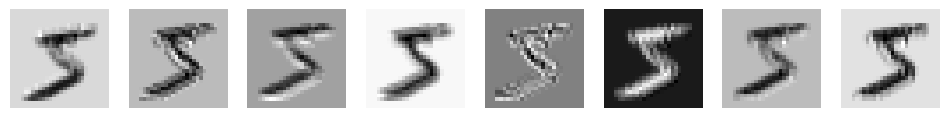

In [5]:
conv_multi = layers.Conv2D(8, (3,3), padding='same', use_bias=False)
out_multi = conv_multi(sample)
print('출력 shape:', out_multi.shape)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i in range(8):
    axes[i].imshow(out_multi[0, :, :, i], cmap='gray')
    axes[i].axis('off')
plt.show()

### 2.4 Bias 항 이해

In [6]:
conv_no_bias = layers.Conv2D(1, (3,3), padding='same', use_bias=False)
conv_with_bias = layers.Conv2D(1, (3,3), padding='same', use_bias=True)

out_no_bias = conv_no_bias(sample)
out_with_bias = conv_with_bias(sample)

bias_value = conv_with_bias.bias.numpy()
print('Bias 값:', bias_value)
print('Bias 적용 전후 차이:', tf.reduce_mean(out_with_bias - out_no_bias).numpy())

Bias 값: [0.]


Bias 적용 전후 차이: 0.3988817


## [3] Pooling 실습

입력: (1, 28, 28, 1)
Max Pool 출력: (1, 14, 14, 1)
Avg Pool 출력: (1, 14, 14, 1)


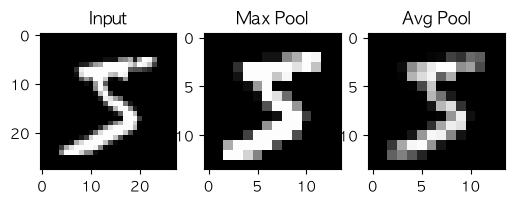

In [7]:
pool_max = layers.MaxPooling2D(pool_size=(2,2), strides=2)
pool_avg = layers.AveragePooling2D(pool_size=(2,2), strides=2)

out_max = pool_max(sample)
out_avg = pool_avg(sample)

print('입력:', sample.shape)
print('Max Pool 출력:', out_max.shape)
print('Avg Pool 출력:', out_avg.shape)

plt.figure(figsize=(6,2))
plt.subplot(1,3,1)
plt.title('Input')
plt.imshow(sample[0].squeeze(), cmap='gray')

plt.subplot(1,3,2)
plt.title('Max Pool')
plt.imshow(np.squeeze(out_max[0]), cmap='gray')

plt.subplot(1,3,3)
plt.title('Avg Pool')
plt.imshow(np.squeeze(out_avg[0]), cmap='gray')
plt.show()


### [생각해보기 - Pooling]
1. Max Pooling과 Average Pooling은 무엇을 남기나요?
2. Pooling이 과적합을 줄인다고 하는 이유는 무엇인가요?


**나의 답변:**

1. Max Pooling은 커널 안에서 가장 큰 값만 남겨 강한 반응을 강조한다.  
   반면 Average Pooling은 값들을 평균 내어 더 부드러운 요약을 만든다.  
   둘 다 2x2 stride 2라 28x28이 14x14로 줄었다.

2. 공간 크기를 줄이면 다음 층의 파라미터와 계산량이 줄어든다.  
   게다가 정확한 픽셀 위치보다 특징의 유무에 기대므로, 외우기보다 일반화하기 쉬워진다.


## [4] CNN 간단 학습 실습

In [8]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.AveragePooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.1, verbose=0)
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print('테스트 정확도:', test_acc)


테스트 정확도: 0.9811999797821045


### [생각해보기 - CNN 학습]
1. CNN이 MLP보다 이미지에 잘 맞는 핵심 이유는 무엇인가요?
2. 필터 개수를 늘리면 무엇이 달라지나요?


**나의 답변:**

1. 이미지는 이웃 픽셀이 서로 연관되고, 같은 무늬가 여러 위치에 반복된다.  
   CNN은 국소 연결과 가중치 공유로 이 가정을 반영하므로, 적은 파라미터로도 잘 배운다.  
   이번 모델은 121,930개 파라미터로 3에포크 만에 테스트 정확도 0.9812를 냈다.

2. 필터가 늘어나면 한 위치에서 여러 종류의 특징 맵이 나온다.  
   즉 엣지, 곡선처럼 서로 다른 패턴을 동시에 추출할 수 있다.
